# NB6.1 — Zero-cost NAS: reproduction of "Neural Architecture Search without Training" on NAS-Bench-201
____________________________________________________________________________________________________

**Paper:** J. Mellor, J. Turner, A. Storkey, E. J. Crowley, *Neural Architecture Search without Training*, ICML 2021 (NASWOT).

**Idea of the paper:** we can predict how good an architecture will be **after training** by looking at it **at initialization**, on a single mini-batch, in a fraction of a second, instead of training it for hours.

Before using this idea on EuroSAT (NB6.2), we check that **our own implementation** gives the same results as the paper. For that we need a search space where the true accuracy of **every** architecture is known: **NAS-Bench-201** (Dong & Yang, 2020), where all 15,625 architectures have been trained on CIFAR-10, CIFAR-100 and ImageNet16-120 (NB6.0 extracted these accuracies to a CSV).

a. The NAS-Bench-201 search space, implemented from scratch

b. The zero-cost proxies: NASWOT (the paper), and for comparison SynFlow, grad-norm, SNIP and the number of parameters

c. **Reproduction 1 — correlation**: score vs trained accuracy for 1000 random architectures (paper: Figure 3, Kendall τ)

d. **Reproduction 2 — the other proxies** (paper of comparison: Abdelfattah et al., *Zero-Cost Proxies for Lightweight NAS*, ICLR 2021, Table 1, Spearman ρ)

e. **Reproduction 3 — search**: NASWOT with N = 10, 100, 1000 sampled architectures, 500 runs (paper: Table 2)

f. Robustness of the score to the mini-batch (paper: Section 3.1)

g. Conclusion

## 0. Setup

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import pandas as pd          # imported after torch (on Windows, pandas first makes torch fail to load its DLLs)
from scipy.stats import kendalltau, spearmanr
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

ON_KAGGLE = os.path.exists("/kaggle/input")

def find_path(name, search_roots):
    # walk the search folders and return the first file / folder called `name`
    for search_root in search_roots:
        for root, dirs, files in os.walk(search_root):
            if name in dirs or name in files:
                return os.path.join(root, name)
    return None

SEARCH_ROOTS = ["/kaggle/input"] if ON_KAGGLE else ["..", "../.."]
OUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
RES_DIR = os.path.join(OUT_DIR, "results")
DATA_DIR = os.path.join(OUT_DIR, "data") if ON_KAGGLE else os.path.join("..", "data")
os.makedirs(RES_DIR, exist_ok=True)

BENCH_CSV = find_path("nasbench201_accuracies.csv", SEARCH_ROOTS)        # from NB6.0
OFFICIAL_INFO_CSV = find_path("nas_bench_201_info_cifar10.csv", SEARCH_ROOTS)   # params / flops published with the benchmark
print("BENCH_CSV        :", BENCH_CSV)
print("OFFICIAL_INFO_CSV:", OFFICIAL_INFO_CSV)

Using device: cuda:0
BENCH_CSV        : /kaggle/input/notebooks/emilioyared/aide500-nb6-0-nasbench201-extract-run-1010-2028/nasbench201_accuracies.csv
OFFICIAL_INFO_CSV: /kaggle/input/datasets/tahsintariq/nas-bench-201-info-cifar10/nas_bench_201_info_cifar10.csv


## a. The NAS-Bench-201 search space

Every architecture has the **same skeleton**; only the **cell** changes.

**Skeleton** (CIFAR, input 32×32):

| part | output |
|---|---|
| stem: Conv 3×3 (3→16) + BN | 16 × 32 × 32 |
| 5 × cell (C = 16) | 16 × 32 × 32 |
| residual block, stride 2 (16→32) | 32 × 16 × 16 |
| 5 × cell (C = 32) | 32 × 16 × 16 |
| residual block, stride 2 (32→64) | 64 × 8 × 8 |
| 5 × cell (C = 64) | 64 × 8 × 8 |
| BN + ReLU, global average pooling, Linear(64 → classes) | classes |

**The cell** is a small graph with 4 nodes. Node 0 is the input of the cell, node 3 its output. Every node $j$ receives the **sum** of an operation applied to every previous node $i < j$:

$$x_j = \sum_{i<j} o_{i,j}(x_i)$$

That is 6 edges, and each edge chooses one of 5 operations:

| name | operation |
|---|---|
| `none` | zero: the edge does not exist |
| `skip_connect` | identity |
| `nor_conv_1x1` | ReLU → Conv 1×1 → BN |
| `nor_conv_3x3` | ReLU → Conv 3×3 → BN |
| `avg_pool_3x3` | average pooling 3×3 |

So $5^6 = 15{,}625$ architectures. An architecture is written as a string, one group per node: `|op~0|+|op~0|op~1|+|op~0|op~1|op~2|` (`op~i` = operation applied to node $i$).

In [2]:
bench = pd.read_csv(BENCH_CSV)
print("number of architectures:", len(bench))
print(bench.head())
best = bench.loc[bench["cifar10_test"].idxmax()]
print("\nbest architecture on CIFAR-10 test (%.2f %%): %s" % (best["cifar10_test"], best["arch"]))

number of architectures: 15625
   index                                               arch  cifar10_valid  \
0      0  |avg_pool_3x3~0|+|nor_conv_1x1~0|skip_connect~...      81.982667   
1      1  |nor_conv_3x3~0|+|nor_conv_3x3~0|avg_pool_3x3~...      90.769333   
2      2  |avg_pool_3x3~0|+|nor_conv_3x3~0|nor_conv_3x3~...      81.910667   
3      3  |avg_pool_3x3~0|+|skip_connect~0|none~1|+|none...      84.377333   
4      4  |skip_connect~0|+|skip_connect~0|nor_conv_1x1~...      85.125333   

   cifar10_test  cifar100_valid  cifar100_test  imagenet16_valid  \
0     85.863333       52.700000      52.913333         28.211111   
1     93.660000       69.826667      70.293333         44.488889   
2     85.740000       54.300000      54.866667         27.633333   
3     86.616667       57.413333      58.306667         29.433333   
4     88.216667       59.566667      60.140000         32.144444   

   imagenet16_test  
0        26.633333  
1        44.033333  
2        27.255555  
3      

**Implementation** (written from the description of the NAS-Bench-201 paper). The 3 building blocks are small `nn.Module` classes, as in the labs.

In [3]:
class ReLUConvBN(nn.Module):
    def __init__(self, C_in, C_out, kernel_size, stride, padding):
        super(ReLUConvBN, self).__init__()
        self.op = nn.Sequential(
            nn.ReLU(inplace=False),
            nn.Conv2d(C_in, C_out, kernel_size, stride=stride, padding=padding, bias=False),
            nn.BatchNorm2d(C_out))

    def forward(self, x):
        return self.op(x)


class Zero(nn.Module):
    def forward(self, x):
        return x.mul(0.)          # 'none': no information goes through this edge


def make_op(name, C):
    if name == "none":
        return Zero()
    if name == "skip_connect":
        return nn.Identity()
    if name == "nor_conv_1x1":
        return ReLUConvBN(C, C, 1, 1, 0)
    if name == "nor_conv_3x3":
        return ReLUConvBN(C, C, 3, 1, 1)                    # padding 1: same size
    if name == "avg_pool_3x3":
        return nn.AvgPool2d(3, stride=1, padding=1, count_include_pad=False)
    raise ValueError(name)


def parse_arch(arch_str):
    # '|nor_conv_3x3~0|+|skip_connect~0|none~1|+|...|' -> [[(op, 0)], [(op, 0), (op, 1)], [(op, 0), (op, 1), (op, 2)]]
    nodes = []
    for node_str in arch_str.split("+"):
        edges = [e for e in node_str.split("|") if e != ""]
        nodes.append([(e.split("~")[0], int(e.split("~")[1])) for e in edges])
    return nodes


class Cell(nn.Module):
    def __init__(self, arch_str, C):
        super(Cell, self).__init__()
        self.nodes = parse_arch(arch_str)
        self.edges = nn.ModuleList()
        for node in self.nodes:
            for op_name, _ in node:
                self.edges.append(make_op(op_name, C))

    def forward(self, x):
        states = [x]                                         # node 0 = input of the cell
        k = 0
        for node in self.nodes:
            s = 0
            for _, i in node:
                s = s + self.edges[k](states[i])            # x_j = sum_i o_ij(x_i)
                k += 1
            states.append(s)
        return states[-1]                                    # node 3 = output of the cell


class ResidualBlock(nn.Module):
    # reduction between two stages: halves the size, doubles the channels
    def __init__(self, C_in, C_out):
        super(ResidualBlock, self).__init__()
        self.conv_a = ReLUConvBN(C_in, C_out, 3, 2, 1)      # h_out = (h + 2 - 3) / 2 + 1 = h / 2
        self.conv_b = ReLUConvBN(C_out, C_out, 3, 1, 1)
        self.downsample = nn.Sequential(
            nn.AvgPool2d(2, 2),
            nn.Conv2d(C_in, C_out, 1, bias=False))

    def forward(self, x):
        return self.downsample(x) + self.conv_b(self.conv_a(x))


class NB201Net(nn.Module):
    def __init__(self, arch_str, num_classes=10, C=16, N=5):
        super(NB201Net, self).__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, C, 3, padding=1, bias=False), nn.BatchNorm2d(C))
        layers = []
        for stage in range(3):
            if stage > 0:
                layers.append(ResidualBlock(C, 2 * C))
                C = 2 * C
            for _ in range(N):
                layers.append(Cell(arch_str, C))
        self.cells = nn.Sequential(*layers)
        self.lastact = nn.Sequential(nn.BatchNorm2d(C), nn.ReLU(inplace=False))
        self.global_pooling = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(C, num_classes)

    def forward(self, x):
        x = self.stem(x)                   # [B, 16, 32, 32]
        x = self.cells(x)                  # [B, 64, 8, 8]
        x = self.lastact(x)
        x = self.global_pooling(x)         # [B, 64, 1, 1]
        x = x.view(-1, x.size(1))          # [B, 64]
        return self.classifier(x)          # [B, classes]


net = NB201Net(best["arch"])
print(net.cells[0])
print("parameters:", sum(p.numel() for p in net.parameters()))
print("output shape:", net(torch.randn(2, 3, 32, 32)).shape)

Cell(
  (edges): ModuleList(
    (0-2): 3 x ReLUConvBN(
      (op): Sequential(
        (0): ReLU()
        (1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (3): Identity()
    (4): ReLUConvBN(
      (op): Sequential(
        (0): ReLU()
        (1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (5): ReLUConvBN(
      (op): Sequential(
        (0): ReLU()
        (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
  )
)
parameters: 1073466
output shape: torch.Size([2, 10])


**Check of our implementation.** The benchmark also publishes the number of parameters of every network. If our networks have **exactly** the same number of parameters for many random architectures, our cell, skeleton and operations are built like the original ones.

In [4]:
official = pd.read_csv(OFFICIAL_INFO_CSV, index_col=0)        # 'params' in millions, same index as the benchmark
check_idx = np.random.RandomState(0).choice(len(bench), 300, replace=False)
ours = np.array([sum(p.numel() for p in NB201Net(bench["arch"][i]).parameters()) / 1e6 for i in check_idx])
theirs = official["params"].values[check_idx]
print("architectures checked: %d | identical number of parameters: %d | max difference: %.6f M" %
      (len(check_idx), (np.abs(ours - theirs) < 1e-6).sum(), np.abs(ours - theirs).max()))

architectures checked: 300 | identical number of parameters: 300 | max difference: 0.000000 M


## b. The zero-cost proxies

All of them are computed on a network **at initialization** (random weights, never trained).

### NASWOT (the paper)

A ReLU network cuts the input space into regions; inside each region the network is linear. For an input image $x_i$, the **binary code** $c_i$ says which ReLUs are active (input > 0 → 1, else 0), over all the $N_A$ ReLUs of the network. Two images with the same code are in the same linear region: the network cannot really separate them.

For a mini-batch of $B$ images, we build the $B \times B$ kernel

$$K_H[i, j] = N_A - d_H(c_i, c_j)$$

($d_H$ = Hamming distance = number of ReLUs that differ). If the network separates the images well, the codes are very different: $K_H$ is close to diagonal. The score is

$$s = \log |K_H|$$

(log of the determinant: large when $K_H$ is close to diagonal). **Higher score → better architecture.**

In practice, with $x$ the 0/1 codes of one ReLU layer ($B \times$ units): $x x^T$ counts the ReLUs active for both images, $(1-x)(1-x)^T$ the ReLUs inactive for both; their sum is $N_A - d_H$. We add this for every ReLU with a **forward hook** (a function PyTorch calls every time the module is used).

In [5]:
def naswot_score(net, inputs):
    B = inputs.size(0)
    K = torch.zeros(B, B, dtype=torch.float64, device=inputs.device)

    def hook(module, inp, out):
        x = (inp[0].view(B, -1) > 0).double()                # binary code of this ReLU layer
        K.add_(x @ x.t() + (1 - x) @ (1 - x).t())            # = units - Hamming distance

    handles = [m.register_forward_hook(hook) for m in net.modules() if isinstance(m, nn.ReLU)]
    with torch.no_grad():
        net(inputs)
    for h in handles:
        h.remove()
    sign, logdet = torch.linalg.slogdet(K)
    return logdet.item() if sign > 0 else -1e6               # singular kernel (e.g. a cell made of 'none' only)

### Other proxies (for comparison)

- **grad-norm**: $\sum_l \|\nabla_{W_l} L\|_2$ — size of the gradients of the loss on one mini-batch.
- **SNIP** (Lee et al., 2019): $\sum |W \odot \nabla_W L|$ — how much the loss would change if each weight were removed.
- **SynFlow** (Tanaka et al., 2020): **no data** at all. All weights are replaced by their absolute value, the input is an image full of 1, and the score is $\sum |W \odot \nabla_W R|$ with $R$ = sum of the outputs. It measures how much "signal" can flow through the network. BatchNorm is put in `eval()` mode (at initialization, its running statistics make it an identity).
- **#params**: the number of parameters, the simplest baseline: bigger networks are often better. A proxy that does not beat it is useless.

In [6]:
def gradient_proxies(net, inputs, labels):
    # grad-norm and SNIP, from the gradient of the cross-entropy on one mini-batch
    net.train()
    net.zero_grad()
    loss = nn.CrossEntropyLoss()(net(inputs), labels)
    loss.backward()
    grad_norm, snip = 0.0, 0.0
    for m in net.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)) and m.weight.grad is not None:
            grad_norm += m.weight.grad.norm().item()
            snip += (m.weight * m.weight.grad).abs().sum().item()
    return grad_norm, snip


def synflow_score(net, input_shape):
    net = net.double()
    net.eval()
    with torch.no_grad():
        for p in net.state_dict().values():
            p.abs_()                                          # all weights positive
    net.zero_grad()
    x = torch.ones((1,) + tuple(input_shape), dtype=torch.float64, device=device)
    torch.sum(net(x)).backward()
    score = 0.0
    for m in net.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)) and m.weight.grad is not None:
            score += (m.weight * m.weight.grad).abs().sum().item()
    return score


def n_params(net):
    return sum(p.numel() for p in net.parameters())

**Mini-batches.** Like the paper, NASWOT uses one mini-batch of **128 training images**; the gradient proxies use 64 images. CIFAR-10 and CIFAR-100 are downloaded with `torchvision`.

**ImageNet16-120** (ImageNet downsampled to 16×16, 120 classes) is not available on Kaggle. To score the networks for this dataset we use **CIFAR-100 images downsampled to 16×16**. The network is the same (it only has 120 outputs), but the images are not the true ones, so this part of the reproduction is only approximate.

In [7]:
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

def get_batch(name, batch_size, seed=0):
    if name == "cifar10":
        dataset = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True,
                                               transform=transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)]))
    elif name == "cifar100":
        dataset = torchvision.datasets.CIFAR100(DATA_DIR, train=True, download=True,
                                                transform=transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)]))
    else:  # "imagenet16": CIFAR-100 images at 16x16 (substitute, see above)
        dataset = torchvision.datasets.CIFAR100(DATA_DIR, train=True, download=True,
                                                transform=transforms.Compose([transforms.Resize(16), transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)]))
    g = torch.Generator()
    g.manual_seed(seed)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=g)
    images, labels = next(iter(loader))
    return images.to(device), labels.to(device)

DATASETS = {
    # name: (number of classes, accuracy column used for the correlation, Kendall tau of the paper)
    "cifar10": (10, "cifar10_valid", 0.574),
    "cifar100": (100, "cifar100_valid", 0.611),
    "imagenet16": (120, "imagenet16_valid", 0.549),
}
batches = {name: get_batch(name, 128) for name in DATASETS}
for name, (x, y) in batches.items():
    print(name, tuple(x.shape))

100%|██████████| 170M/170M [26:46<00:00, 106kB/s] 
100%|██████████| 169M/169M [28:28<00:00, 98.9kB/s]


cifar10 (128, 3, 32, 32)
cifar100 (128, 3, 32, 32)
imagenet16 (128, 3, 16, 16)


## c. Reproduction 1 — does the score predict the trained accuracy?

As in Figure 3 of the paper: **1000 random architectures**, score at initialization on one mini-batch of the dataset, against the **validation accuracy after 200 epochs of training** (from the benchmark). We measure the agreement of the two rankings with **Kendall's τ**:

$$\tau = \frac{\#\text{concordant pairs} - \#\text{discordant pairs}}{\#\text{pairs}}$$

(a pair of architectures is concordant if the one with the higher score also has the higher accuracy). τ = 1: same ranking, τ = 0: no relation.

In [8]:
sample_idx = np.random.RandomState(1).choice(len(bench), 1000, replace=False)
naswot = {}
for name, (num_classes, acc_col, paper_tau) in DATASETS.items():
    x, _ = batches[name]
    start = time.time()
    scores = []
    for k, i in enumerate(sample_idx):
        set_seed(k)
        net = NB201Net(bench["arch"][i], num_classes).to(device)
        scores.append(naswot_score(net, x))
    naswot[name] = np.array(scores)
    tau = kendalltau(naswot[name], bench[acc_col].values[sample_idx])[0]
    print('%-11s Kendall tau: ours %.3f | paper %.3f | %.1f ms per architecture' %
          (name, tau, paper_tau, (time.time() - start) / len(sample_idx) * 1000))

cifar10     Kendall tau: ours 0.602 | paper 0.574 | 164.1 ms per architecture
cifar100    Kendall tau: ours 0.640 | paper 0.611 | 161.6 ms per architecture
imagenet16  Kendall tau: ours 0.600 | paper 0.549 | 59.3 ms per architecture


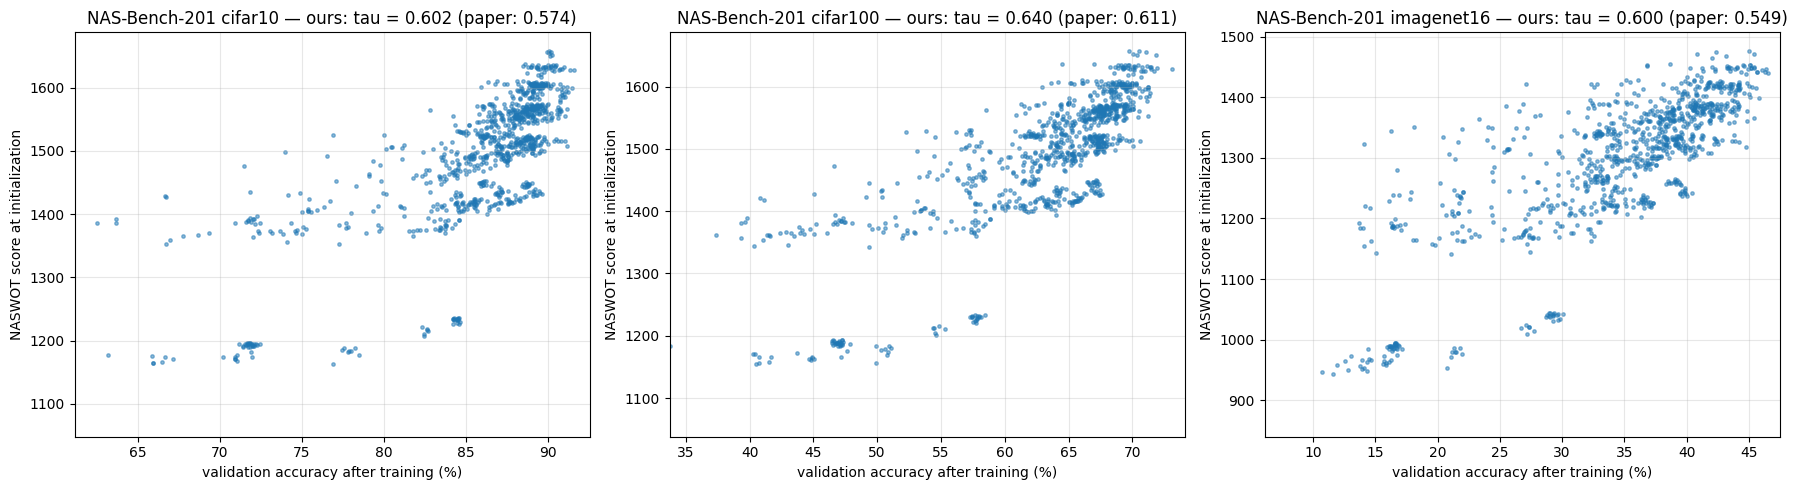

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (num_classes, acc_col, paper_tau)) in zip(axes, DATASETS.items()):
    acc = bench[acc_col].values[sample_idx]
    ok = naswot[name] > 0                                        # hide the few singular kernels (score = -1e6)
    tau = kendalltau(naswot[name], acc)[0]
    ax.scatter(acc[ok], naswot[name][ok], s=6, alpha=0.5)
    ax.set_xlabel("validation accuracy after training (%)"); ax.set_ylabel("NASWOT score at initialization")
    ax.set_title("NAS-Bench-201 %s — ours: tau = %.3f (paper: %.3f)" % (name, tau, paper_tau))
    ax.set_xlim(max(acc.min(), np.percentile(acc, 5) - 10), acc.max() + 1)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## d. Reproduction 2 — the other proxies

Abdelfattah et al. (2021) computed several proxies on NAS-Bench-201 and report the **Spearman ρ** (correlation of the ranks) with the final **test** accuracy. We compute ours on the same 1000 CIFAR-10 architectures, plus NASWOT and the number of parameters.

In [10]:
PAPER_RHO = {"grad_norm": 0.58, "snip": 0.58, "synflow": 0.74, "naswot": None, "params": None}
x64, y64 = get_batch("cifar10", 64, seed=1)
proxies = {"grad_norm": [], "snip": [], "synflow": [], "params": []}
start = time.time()
for k, i in enumerate(sample_idx):
    set_seed(k)
    net = NB201Net(bench["arch"][i], 10).to(device)
    gn, sn = gradient_proxies(net, x64, y64)
    proxies["grad_norm"].append(gn)
    proxies["snip"].append(sn)
    proxies["params"].append(n_params(net))
    set_seed(k)
    proxies["synflow"].append(synflow_score(NB201Net(bench["arch"][i], 10).to(device), (3, 32, 32)))
proxies["naswot"] = naswot["cifar10"]
print("%.1f ms per architecture for the 3 gradient proxies" % ((time.time() - start) / len(sample_idx) * 1000))

test_acc = bench["cifar10_test"].values[sample_idx]
print('\n%-10s %12s %14s %12s' % ('proxy', 'Spearman rho', 'paper (ICLR21)', 'Kendall tau'))
proxy_corr = {}
for name, values in proxies.items():
    rho, tau = spearmanr(values, test_acc)[0], kendalltau(values, test_acc)[0]
    proxy_corr[name] = {"spearman": rho, "kendall": tau}
    print('%-10s %12.3f %14s %12.3f' % (name, rho, "%.2f" % PAPER_RHO[name] if PAPER_RHO[name] else "-", tau))

109.4 ms per architecture for the 3 gradient proxies

proxy      Spearman rho paper (ICLR21)  Kendall tau
grad_norm         0.649           0.58        0.476
snip              0.652           0.58        0.480
synflow           0.801           0.74        0.605
params            0.763              -        0.583
naswot            0.806              -        0.619


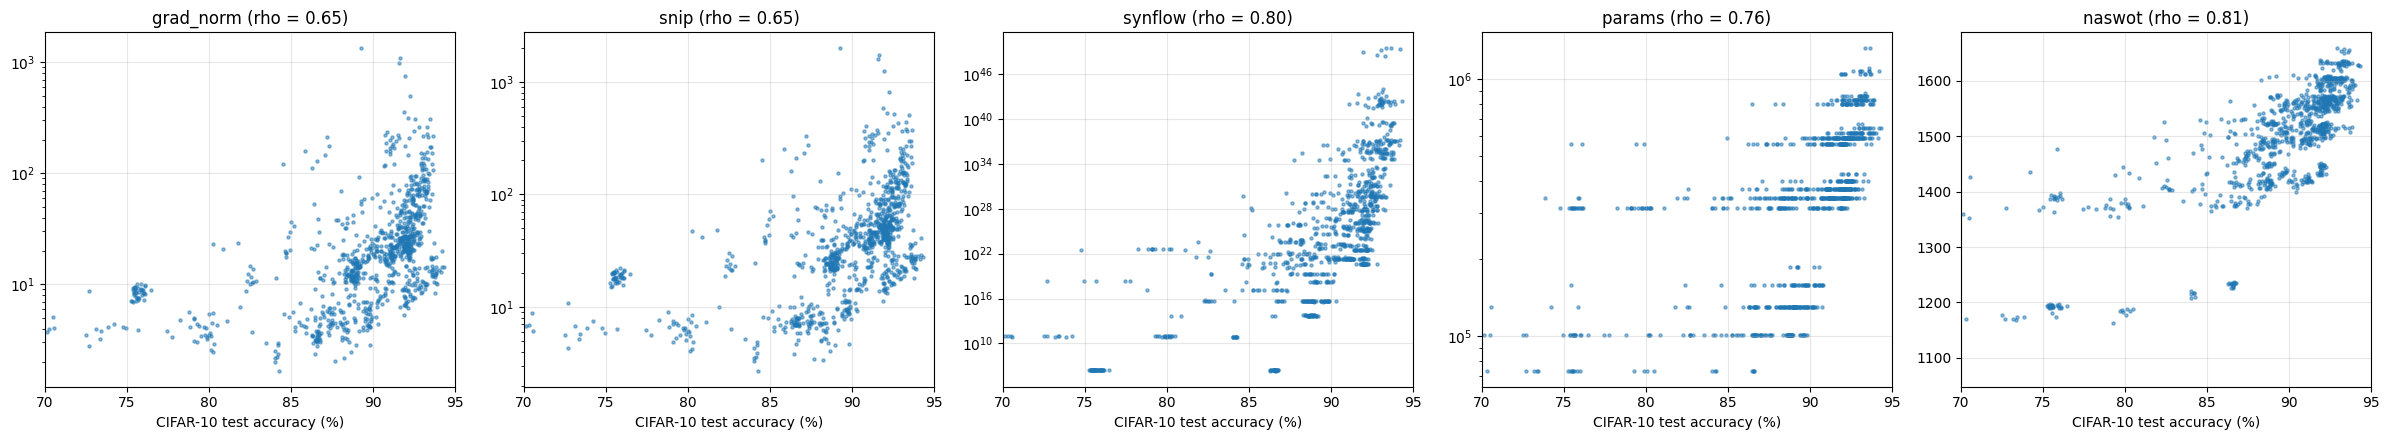

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
for ax, (name, values) in zip(axes, proxies.items()):
    values = np.array(values, dtype=float)
    ok = values > 0
    ax.scatter(test_acc[ok], values[ok], s=5, alpha=0.5)
    if name in ("synflow", "snip", "grad_norm", "params"):
        ax.set_yscale("log")
    ax.set_title("%s (rho = %.2f)" % (name, proxy_corr[name]["spearman"]))
    ax.set_xlabel("CIFAR-10 test accuracy (%)"); ax.set_xlim(70, 95); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## e. Reproduction 3 — search with NASWOT (Algorithm 1 of the paper)

The search algorithm is very simple:

```
sample N random architectures
score each one at initialization (NASWOT)
return the one with the highest score
```

The paper repeats this **500 times** for N = 10, 100 and 1000, always scoring on **CIFAR-10**, and reports the mean ± std accuracy of the chosen architecture on the 3 datasets (Table 2).

To make 500 runs affordable, we **score the 15,625 architectures once** (one CIFAR-10 mini-batch, one initialization per architecture), and each run then samples N of them and takes the best score. The paper draws a new mini-batch for every run; Section f shows that the score hardly depends on the mini-batch, so this simplification should not change the result.

We also report two references, like the paper: **Random** (one architecture at random, i.e. the mean over the benchmark) and **Optimal (N)** (the best accuracy among the N sampled architectures: what a perfect proxy would find).

In [12]:
x, _ = batches["cifar10"]
start = time.time()
all_scores = np.zeros(len(bench))
for i in range(len(bench)):
    set_seed(i)
    all_scores[i] = naswot_score(NB201Net(bench["arch"][i], 10).to(device), x)
    if (i + 1) % 2500 == 0:
        print("%5d architectures scored | %.0f s" % (i + 1, time.time() - start))
time_per_arch = (time.time() - start) / len(bench)
print("scoring time: %.1f ms per architecture" % (time_per_arch * 1000))
bench["naswot_cifar10"] = all_scores
bench.to_csv(os.path.join(RES_DIR, "NB6_1_nasbench201_naswot_scores.csv"), index=False)
print("Kendall tau on the whole benchmark (CIFAR-10 valid): %.3f" % kendalltau(all_scores, bench["cifar10_valid"])[0])

 2500 architectures scored | 399 s
 5000 architectures scored | 801 s
 7500 architectures scored | 1199 s
10000 architectures scored | 1598 s
12500 architectures scored | 1996 s
15000 architectures scored | 2405 s
scoring time: 160.4 ms per architecture
Kendall tau on the whole benchmark (CIFAR-10 valid): 0.589


In [13]:
ACC_COLS = ["cifar10_valid", "cifar10_test", "cifar100_valid", "cifar100_test", "imagenet16_valid", "imagenet16_test"]
PAPER_TABLE2 = {
    "NASWOT (N=10)":   [(89.14, 1.14), (92.44, 1.13), (68.50, 2.03), (68.62, 2.04), (41.09, 3.97), (41.31, 4.11)],
    "NASWOT (N=100)":  [(89.55, 0.89), (92.81, 0.99), (69.35, 1.70), (69.48, 1.70), (42.81, 3.05), (43.10, 3.16)],
    "NASWOT (N=1000)": [(89.69, 0.73), (92.96, 0.81), (69.86, 1.21), (69.98, 1.22), (43.95, 2.05), (44.44, 2.10)],
    "Random":          [(83.20, 13.28), (86.61, 13.46), (60.70, 12.55), (60.83, 12.58), (33.34, 9.39), (33.13, 9.66)],
    "Optimal (N=10)":  [(89.92, 0.75), (93.06, 0.59), (69.61, 1.21), (69.76, 1.25), (43.11, 1.85), (43.30, 1.87)],
    "Optimal (N=100)": [(91.05, 0.28), (93.84, 0.23), (71.45, 0.79), (71.56, 0.78), (45.37, 0.61), (45.67, 0.64)],
}
N_RUNS = 500
rng = np.random.RandomState(SEED)
accs = bench[ACC_COLS].values
ours_table = {}
for N in [10, 100, 1000]:
    chosen, optimal = [], []
    for run in range(N_RUNS):
        idx = rng.choice(len(bench), N, replace=False)
        chosen.append(accs[idx[np.argmax(all_scores[idx])]])   # NASWOT: highest score
        optimal.append(accs[idx].max(axis=0))                   # best possible in the sample
    ours_table["NASWOT (N=%d)" % N] = (np.mean(chosen, axis=0), np.std(chosen, axis=0), N * time_per_arch)
    if N < 1000:
        ours_table["Optimal (N=%d)" % N] = (np.mean(optimal, axis=0), np.std(optimal, axis=0), None)
ours_table["Random"] = (accs.mean(axis=0), accs.std(axis=0), None)

head = ["C10 valid", "C10 test", "C100 valid", "C100 test", "IN16 valid", "IN16 test"]
print('%-16s %-6s %10s ' % ('method', '', 'search (s)') + ' '.join('%14s' % h for h in head))
print('-' * 135)
for method in PAPER_TABLE2:
    mean, std, search_time = ours_table[method]
    print('%-16s %-6s %10s ' % (method, 'ours', "%.2f" % search_time if search_time else "-") + ' '.join('%7.2f +- %4.2f' % (m, s) for m, s in zip(mean, std)))
    print('%-16s %-6s %10s ' % ('', 'paper', '') + ' '.join('%7.2f +- %4.2f' % ms for ms in PAPER_TABLE2[method]))

method                  search (s)      C10 valid       C10 test     C100 valid      C100 test     IN16 valid      IN16 test
---------------------------------------------------------------------------------------------------------------------------------------
NASWOT (N=10)    ours         1.60   89.10 +- 1.20   92.39 +- 1.20   68.53 +- 2.25   68.63 +- 2.31   41.09 +- 3.74   41.29 +- 3.94
                 paper               89.14 +- 1.14   92.44 +- 1.13   68.50 +- 2.03   68.62 +- 2.04   41.09 +- 3.97   41.31 +- 4.11
NASWOT (N=100)   ours        16.04   89.58 +- 0.84   92.83 +- 0.94   69.41 +- 1.59   69.52 +- 1.67   42.87 +- 2.82   43.18 +- 2.95
                 paper               89.55 +- 0.89   92.81 +- 0.99   69.35 +- 1.70   69.48 +- 1.70   42.81 +- 3.05   43.10 +- 3.16
NASWOT (N=1000)  ours       160.38   89.65 +- 0.93   92.91 +- 1.03   69.71 +- 1.50   69.84 +- 1.42   43.50 +- 2.61   43.99 +- 2.70
                 paper               89.69 +- 0.73   92.96 +- 0.81   69.86 +- 1.21  

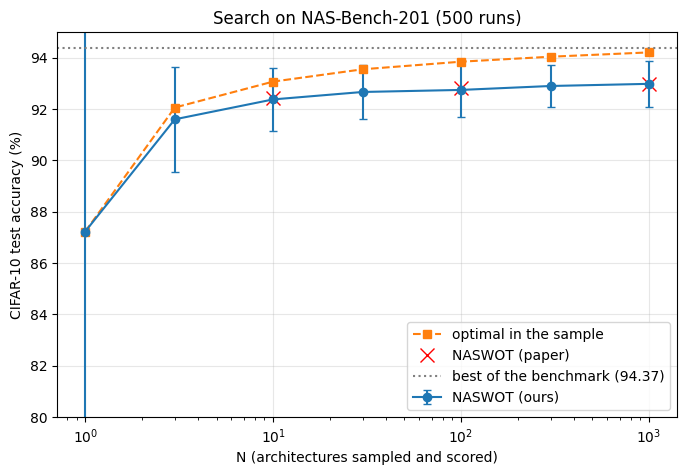

In [14]:
# accuracy of the chosen architecture as a function of N (CIFAR-10 test)
Ns = [1, 3, 10, 30, 100, 300, 1000]
rng = np.random.RandomState(SEED)
mean_naswot, std_naswot, mean_opt = [], [], []
for N in Ns:
    chosen, optimal = [], []
    for run in range(N_RUNS):
        idx = rng.choice(len(bench), N, replace=False)
        chosen.append(bench["cifar10_test"].values[idx[np.argmax(all_scores[idx])]])
        optimal.append(bench["cifar10_test"].values[idx].max())
    mean_naswot.append(np.mean(chosen)); std_naswot.append(np.std(chosen)); mean_opt.append(np.mean(optimal))

plt.figure(figsize=(8, 5))
plt.errorbar(Ns, mean_naswot, yerr=std_naswot, fmt="o-", capsize=3, label="NASWOT (ours)")
plt.plot(Ns, mean_opt, "s--", label="optimal in the sample")
plt.plot([10, 100, 1000], [92.44, 92.81, 92.96], "x", ms=10, color="red", label="NASWOT (paper)")
plt.axhline(bench["cifar10_test"].max(), color="grey", ls=":", label="best of the benchmark (%.2f)" % bench["cifar10_test"].max())
plt.xscale("log"); plt.xlabel("N (architectures sampled and scored)"); plt.ylabel("CIFAR-10 test accuracy (%)")
plt.title("Search on NAS-Bench-201 (500 runs)"); plt.ylim(80, 95); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## f. Is the score robust to the mini-batch?

Section 3.1 of the paper: the score of an architecture barely changes with the mini-batch, so the ranking of the architectures is stable. We score 100 random architectures with 5 different CIFAR-10 mini-batches and compare the rankings.

Kendall tau between the rankings of 2 different mini-batches: mean 0.991 (min 0.987)


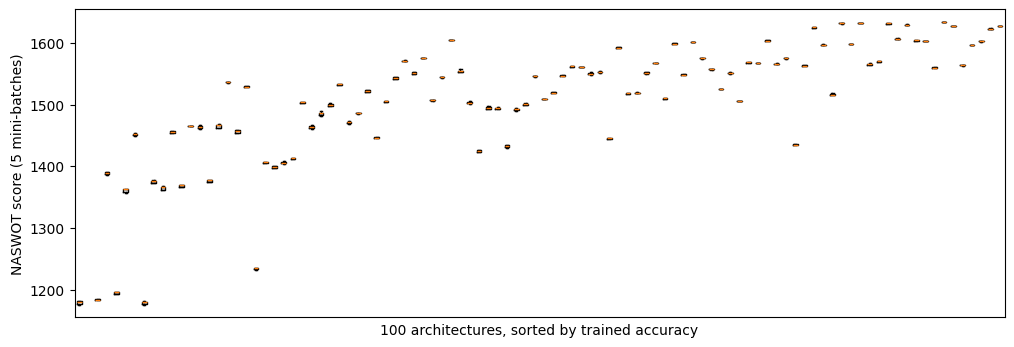

In [15]:
small_idx = np.random.RandomState(2).choice(len(bench), 100, replace=False)
multi = np.zeros((5, len(small_idx)))
for b in range(5):
    x_b, _ = get_batch("cifar10", 128, seed=100 + b)
    for k, i in enumerate(small_idx):
        set_seed(k)                                      # same initialization, only the mini-batch changes
        multi[b, k] = naswot_score(NB201Net(bench["arch"][i], 10).to(device), x_b)

taus = [kendalltau(multi[a], multi[b])[0] for a in range(5) for b in range(a + 1, 5)]
print("Kendall tau between the rankings of 2 different mini-batches: mean %.3f (min %.3f)" % (np.mean(taus), np.min(taus)))
order = np.argsort(bench["cifar10_valid"].values[small_idx])
plt.figure(figsize=(12, 4))
plt.boxplot(multi[:, order], showfliers=False)
plt.xticks([]); plt.xlabel("100 architectures, sorted by trained accuracy"); plt.ylabel("NASWOT score (5 mini-batches)")
plt.ylim(np.percentile(multi[multi > 0], 1) - 20, multi.max() + 20)
plt.show()

## g. Conclusion

We compare our numbers with the paper's in the tables above. Small differences are expected: different random initializations and mini-batches, the 1000 sampled architectures are not the same, and for the search we score each architecture only once.

In [16]:
summary = {
    "kendall_tau": {name: {"ours": float(kendalltau(naswot[name], bench[DATASETS[name][1]].values[sample_idx])[0]), "paper": DATASETS[name][2]} for name in DATASETS},
    "proxies_cifar10": {name: {"ours_spearman": float(v["spearman"]), "ours_kendall": float(v["kendall"]), "paper_spearman": PAPER_RHO[name]} for name, v in proxy_corr.items()},
    "search": {method: {"ours_mean": [float(m) for m in ours_table[method][0]], "ours_std": [float(s) for s in ours_table[method][1]],
                        "paper": PAPER_TABLE2[method]} for method in PAPER_TABLE2},
    "ms_per_architecture": time_per_arch * 1000,
    "batch_robustness_tau": float(np.mean(taus)),
}
with open(os.path.join(RES_DIR, "NB6_1_reproduction.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary["kendall_tau"], indent=1))

{
 "cifar10": {
  "ours": 0.6020694814473407,
  "paper": 0.574
 },
 "cifar100": {
  "ours": 0.6404543433051498,
  "paper": 0.611
 },
 "imagenet16": {
  "ours": 0.6003371742814594,
  "paper": 0.549
 }
}
